# Aprendizaje por Refuerzo (APR): Ping Pong 

En este notebook dos agentes aprenden a jugar un Pong simplificado jugando entre sí, sin conocimiento previo.

## Agente y entorno

- **Agente**: el que aprende y toma decisiones (clase `Agent`).
- **Entorno**: todo con lo que el agente interactúa: la cancha, la pelota y las paletas (clase `Board`).

## Los cuatro subelementos esenciales de un sistema de APR

Además del agente y del entorno, existen cuatro subelementos esenciales:

### 1. Política
La política define completamente el comportamiento de un agente.es el método Agent.move(). 
Dado el estado del tablero, elige entre *subir-0*, *quedarse-1* o *bajar-2*. 
Es una política **ε-greedy**: con probabilidad prob_exp explora (acción al azar) y, 
si no,elige la acción que lleva al estado de mayor valor.

### 2. Recompensa
Es el valor principal a tener en cuenta a la hora de alterar la política de un agente.
se da al final de cada partido en `Game.reward()`: **+1** al ganador y **-1** al perdedor. 
Es una recompensa *escasa*: no hay señal durante el juego, solo al terminar.

### 3. Función de valor
El agente prefiere acciones de mayor valor, aunque den menos recompensa inmediata, pero estimar esos valores exige explorar el entorno muchas veces.
es el diccionario Agent.value_function (estado → valor). Se actualiza en Agent.reward() 
con V(s) ← V(s) + α · (objetivo − V(s)), recorriendo los estados de atrás hacia adelante para 
repartir el resultado final entre todos los estados que llevaron a él.

### 4. Modelo del entorno
El modelo imita el entorno y permite planificar con estados futuros aún no vividos. Según se use o no, los métodos de APR son
con modelo o sin modelo (prueba y error), aunque la línea es difusa.
el aprendizaje es por prueba y error (self-play), es decir, sin modelo. Solo en Agent.move() 
hay una simulación de un paso, escrita a mano, que el agente no aprende ni usa para planificar más allá.

### Regla de actualización (implementación incremental)
Q(s) = Q(s) + alpha * [Recompensa - Q(s)]

Es la forma en que el agente corrige su estimación del valor de un estado después de ver un resultado.

- **Q(s)**: el valor guardado para el estado s (value_function[p] en el código).
- **Recompensa**: lo que realmente pasó (+1 si ganó, -1 si perdió); es el objetivo.
- **[Recompensa - Q(s)]**: el error, es decir, cuánto se equivocó la estimación.
- **alpha**: tasa de aprendizaje; qué parte del error se corrige (con `alpha = 0.5`, la mitad).

**Ejemplo** con `alpha = 0.5` y un estado que valía 0:
- Gana (+1): `0 + 0.5 · (1 − 0) = 0.5`
- Vuelve a ganar (+1): `0.5 + 0.5 · (1 − 0.5) = 0.75`
- Pierde (-1): `0.75 + 0.5 · (−1 − 0.75) = −0.125`

El valor se va acercando a lo que ocurre en promedio desde ese estado.
**Incremental** significa que no se guardan todos los resultados para promediarlos al final: en cada partido se ajusta un poco el valor que ya existe.
La actualización se aplica de atrás hacia adelante: el último estado usa la recompensa real como objetivo, y cada estado anterior usa como objetivo el valor ya actualizado del siguiente (`reward = self.value_function[p]`). Así el resultado final se reparte por toda la cadena de estados.


## Entorno: `Board`

Define las reglas del juego: el movimiento de la pelota y las paletas, el rebote en las paredes y cuándo se anota un punto. La paleta solo devuelve la pelota si está **exactamente** en su misma fila.

- **Estado**: `(bx, by, bvx, bvy, p1_y, p2_y)`, es decir, posición y velocidad de la pelota y posición de ambas paletas.
- **Acciones**: `0` subir, `1` quedarse, `2` bajar.

In [8]:
import numpy as np
from tqdm import tqdm
import os
import time
from IPython.display import clear_output

class Board():
    def __init__(self, width=10, height=10):
        self.width = width
        self.height = height
        self.reset()

    def reset(self):
        # Posición inicial de la pelota en el centro
        self.bx = self.width // 2
        self.by = self.height // 2
        self.bvx = np.random.choice([-1, 1])
        self.bvy = np.random.choice([-1, 0, 1])
        
        # Paleta del Jugador 1 (izquierda) y Jugador 2 (derecha)
        self.p1_y = self.height // 2
        self.p2_y = self.height // 2

    def valid_moves(self):
        # 0: Subir, 1: Quedarse, 2: Bajar
        return [0, 1, 2]

    def update(self, p1_action, p2_action):
        # 1. Mover paleta del Jugador 1
        if p1_action == 0 and self.p1_y > 0:
            self.p1_y -= 1
        elif p1_action == 2 and self.p1_y < self.height - 1:
            self.p1_y += 1
            
        # 2. Mover paleta del Jugador 2
        if p2_action == 0 and self.p2_y > 0:
            self.p2_y -= 1
        elif p2_action == 2 and self.p2_y < self.height - 1:
            self.p2_y += 1

        # 3. Mover la pelota
        self.bx += self.bvx
        self.by += self.bvy

        # 4. Rebote en paredes superior e inferior
        if self.by <= 0:
            self.by = 0
            self.bvy *= -1
        elif self.by >= self.height - 1:
            self.by = self.height - 1
            self.bvy *= -1

    def is_game_over(self):
        # Si la pelota llega al borde izquierdo (lado del Jugador 1)
        if self.bx <= 0:
            if self.p1_y == self.by:
                self.bx = 0
                self.bvx *= -1
                return None # La devuelve, sigue el juego
            else:
                return -1   # Gana el Jugador 2 (el 1 falló)
                
        # Si la pelota llega al borde derecho (lado del Jugador 2)
        elif self.bx >= self.width - 1:
            if self.p2_y == self.by:
                self.bx = self.width - 1
                self.bvx *= -1
                return None # La devuelve, sigue el juego
            else:
                return 1    # Gana el Jugador 1 (el 2 falló)
        return None
    
    def render(self):
        # Limpiar la pantalla de la consola o salida
        os.system('cls' if os.name == 'nt' else 'clear')
        
        # Crear cuadrícula vacía
        grid = [[" " for _ in range(self.width)] for _ in range(self.height)]
        
        # Dibujar paleta Jugador 1 (columna 0)
        grid[self.p1_y][0] = "|"
        
        # Dibujar paleta Jugador 2 (última columna)
        grid[self.p2_y][self.width - 1] = "|"
        
        # Dibujar pelota (si está dentro del rango)
        if 0 <= self.by < self.height and 0 <= self.bx < self.width:
            grid[self.by][self.bx] = "O"
            
        # Imprimir el tablero con marco
        print("+" + "-" * self.width + "+")
        for row in grid:
            print("|" + "".join(row) + "|")
        print("+" + "-" * self.width + "+")

## Game

Los dos agentes juegan entre sí miles de partidos (gana el primero en llegar a 3 puntos). No se necesita un rival humano ni datos previos: ambos mejoran a la vez.

Al terminar cada partido, `reward()` entrega la **recompensa** (+1 / -1) a cada agente.

In [9]:
class Game():
    def __init__(self, player1, player2, target_score=3):
        player1.symbol = 1   # Identificador para Jugador 1
        player2.symbol = -1  # Identificador para Jugador 2
        self.players = [player1, player2]
        self.board = Board(width=25, height=12) # Ancho ampliado para mejor proporción
        self.target_score = target_score        # Gana el primero en llegar a 3 puntos

    def selfplay(self, rounds=1000, max_steps_per_point=50):
        match_wins = [0, 0]
        historial_p1 = []
        historial_p2 = []
        
        for i in range(1, rounds + 1):
            scores = [0, 0]
            for player in self.players:
                player.reset()
                
            match_over = False
            match_winner = None
            
            while not match_over:
                self.board.reset()
                game_over = False
                step_count = 0
                point_winner = None

                while not game_over and step_count < max_steps_per_point:
                    action1 = self.players[0].move(self.board)
                    action2 = self.players[1].move(self.board)

                    for player in self.players:
                        player.update(self.board)

                    self.board.update(action1, action2)

                    res = self.board.is_game_over()
                    if res is not None:
                        game_over = True
                        point_winner = res
                        
                    step_count += 1

                if point_winner == 1:
                    scores[0] += 1
                elif point_winner == -1:
                    scores[1] += 1

                if scores[0] >= self.target_score:
                    match_over = True
                    match_winner = 1
                elif scores[1] >= self.target_score:
                    match_over = True
                    match_winner = -1

            self.reward(match_winner)
            
            if match_winner == 1:
                match_wins[0] += 1
            elif match_winner == -1:
                match_wins[1] += 1
                
            # Registrar el porcentaje de victorias de ambos cada 50 rondas
            if i % 50 == 0:
                historial_p1.append(match_wins[0] / i)
                historial_p2.append(match_wins[1] / i)
                
        return match_wins, historial_p1, historial_p2
        

    def reward(self, winner):
        for player in self.players:
            if winner == player.symbol:
                player.reward(1.0)  # Recompensa al ganador del partido
            else:
                player.reward(-1.0) # Castigo al perdedor del partido

    def play_and_show(self, max_steps=50, delay=0.15):
        # Función para visualizar un partido completo en vivo en Jupyter
        scores = [0, 0]
        match_over = False
        point_num = 1

        print("¡Iniciando partido de exhibición (Primer a 3 puntos)!")
        time.sleep(1)

        while not match_over:
            self.board.reset()
            game_over = False
            step_count = 0
            point_winner = None

            while not game_over and step_count < max_steps:
                action1 = self.players[0].move(self.board, explore=False)
                action2 = self.players[1].move(self.board, explore=False)

                self.board.update(action1, action2)

                clear_output(wait=True)
                self.board.render()
                print(f"--- PUNTO {point_num} ---")
                print(f"Marcador | Jugador 1 (Izquierda): {scores[0]}  vs  Jugador 2 (Derecha): {scores[1]}")
                print(f"Pelota en: ({self.board.bx}, {self.board.by})")
                
                time.sleep(delay)

                res = self.board.is_game_over()
                if res is not None:
                    game_over = True
                    point_winner = res
                    
                step_count += 1

            # Actualizar puntos del partido visual
            if point_winner == 1:
                scores[0] += 1
                print("\n¡Punto para el Jugador 1!")
            elif point_winner == -1:
                scores[1] += 1
                print("\n¡Punto para el Jugador 2!")
            else:
                print("\nPunto anulado por límite de pasos.")

            time.sleep(1.5)
            point_num += 1

            # Verificar si alguien ganó el partido al llegar a 3
            if scores[0] >= self.target_score:
                match_over = True
                clear_output(wait=True)
                print(f"==================================================")
                print(f" ¡EL JUGADOR 1 GANA EL PARTIDO {scores[0]} - {scores[1]}! ")
                print(f"==================================================")
            elif scores[1] >= self.target_score:
                match_over = True
                clear_output(wait=True)
                print(f"==================================================")
                print(f" ¡EL JUGADOR 2 GANA EL PARTIDO {scores[1]} - {scores[0]}! ")
                print(f"==================================================")

## Agente: Agent

Aquí viven la **política** (move) y la **función de valor** (value_function y reward`).

**Exploración vs. explotación (ε-greedy):**
- Con probabilidad prob_exp el agente explora (acción aleatoria).
- Si no, explota: simula cada acción y elige la que lleva al estado de mayor valor.

**Parámetro alpha:** tasa de aprendizaje, cuánto se acerca el valor al objetivo en cada actualización.

In [10]:
class Agent():
    def __init__(self, alpha=0.5, prob_exp=0.5):
        self.value_function = {} # Tabla estado -> valor
        self.alpha = alpha       # Tasa de aprendizaje
        self.positions = []      # Historial de estados de la partida
        self.prob_exp = prob_exp # Probabilidad de exploración

    def reset(self):
        self.positions = []

    def move(self, board, explore=True):
        valid_moves = board.valid_moves()
        
        # Exploración
        if explore and np.random.uniform(0, 1) < self.prob_exp:
            ix = np.random.choice(len(valid_moves))
            return valid_moves[ix]
        
        # Explotación
        max_value = -1000
        best_move = valid_moves[0]
        
        for move in valid_moves:
            # Simular el movimiento según el rol del jugador
            temp_bx, temp_by = board.bx, board.by
            temp_bvx, temp_bvy = board.bvx, board.bvy
            temp_p1, temp_p2 = board.p1_y, board.p2_y
            
            if self.symbol == 1:
                if move == 0 and temp_p1 > 0: temp_p1 -= 1
                elif move == 2 and temp_p1 < board.height - 1: temp_p1 += 1
            else:
                if move == 0 and temp_p2 > 0: temp_p2 -= 1
                elif move == 2 and temp_p2 < board.height - 1: temp_p2 += 1
            
            temp_bx += temp_bvx
            temp_by += temp_bvy
            if temp_by <= 0: temp_by = 0; temp_bvy *= -1
            elif temp_by >= board.height - 1: temp_by = board.height - 1; temp_bvy *= -1
            
            next_state = (temp_bx, temp_by, temp_bvx, temp_bvy, temp_p1, temp_p2)
            value = 0 if self.value_function.get(next_state) is None else self.value_function.get(next_state)
            
            if value >= max_value:
                max_value = value
                best_move = move
                
        return best_move

    def update(self, board):
        state_key = (board.bx, board.by, board.bvx, board.bvy, board.p1_y, board.p2_y)
        self.positions.append(state_key)

    def reward(self, reward):
        # Implementación incremental: Q(s) = Q(s) + alpha * [Recompensa - Q(s)]
        for p in reversed(self.positions):
            if self.value_function.get(p) is None:
                self.value_function[p] = 0.0
            
            # Fórmula de actualización incremental
            self.value_function[p] += self.alpha * (reward - self.value_function[p])
            
            # Propagar el valor actualizado como objetivo para el estado anterior
            reward = self.value_function[p]


## Entrenamiento

Se crean dos agentes con 60% de exploración y se entrenan con 30.000 partidos de self-play. `selfplay` devuelve las victorias de cada uno y el historial de tasa de victorias.

In [11]:
# --- Ejecución de prueba ---
agent1 = Agent(prob_exp=0.6)
agent2 = Agent(prob_exp=0.6)

game = Game(agent1, agent2)

wins, historial_p1, historial_p2 = game.selfplay(rounds=30000)
print(f"Victorias - Agent 1: {wins[0]} | Agent 2: {wins[1]}")

Victorias - Agent 1: 15007 | Agent 2: 14993


## Evolución del aprendizaje

Tasa de victorias de cada jugador cada 50 partidos. Como ambos son iguales y juegan entre sí, es normal que ronden el 50%.

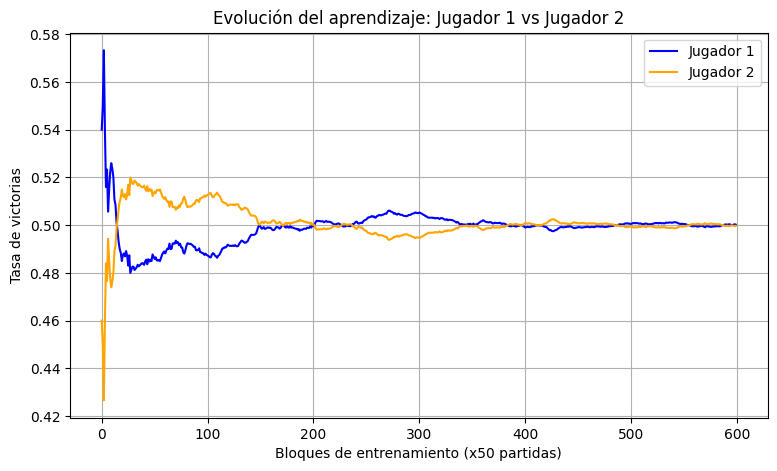

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.plot(historial_p1, label='Jugador 1', color='blue')
plt.plot(historial_p2, label='Jugador 2', color='orange')

plt.legend()
plt.grid(True)
plt.xlabel('Bloques de entrenamiento (x50 partidas)')
plt.ylabel('Tasa de victorias')
plt.title('Evolución del aprendizaje: Jugador 1 vs Jugador 2')
plt.show()

## Función de valor aprendida

Estados ordenados de mayor a menor valor. Los de arriba son situaciones favorables para el agente (suele terminar ganando); los de abajo, situaciones donde suele perder.

In [13]:
import pandas as pd

funcion_de_valor = sorted(agent1.value_function.items(), key=lambda kv: kv[1], reverse=True)
tabla = pd.DataFrame({'estado': [x[0] for x in funcion_de_valor], 'valor': [x[1] for x in funcion_de_valor]})

tabla

,estado,valor
0,"(23, 5, 1, 1, 11, 1)",0.993987
1,"(23, 7, 1, 1, 11, 6)",0.952286
2,"(23, 5, 1, -1, 4, 11)",0.906493
3,"(23, 7, 1, 1, 3, 6)",0.889515
4,"(23, 5, 1, -1, 7, 9)",0.889293
...,...,...
25318,"(1, 5, -1, 1, 3, 9)",-0.873678
25319,"(1, 7, -1, 1, 0, 8)",-0.877614
25320,"(1, 6, -1, 0, 0, 0)",-0.884574
25321,"(1, 7, -1, 1, 10, 4)",-0.946735


## Partido de exhibición

Los agentes juegan con `explore=False`: usan solo lo aprendido, sin acciones aleatorias.

In [15]:
game.play_and_show(max_steps=50, delay=0.15)

 ¡EL JUGADOR 2 GANA EL PARTIDO 3 - 1! 


## Guardar el agente entrenado

La función de valor es todo lo que el agente aprendió. Con `pickle` se guarda el diccionario `agent1.value_function` en el archivo 
`agente.pickle`, así no hay que repetir los 30.000 partidos de entrenamiento cada vez.
Solo se guarda la **función de valor**, no el objeto `Agent` completo. Para reutilizarla, se crea un agente nuevo y se le asigna esa tabla:


In [16]:
import pickle

with open('agente.pickle', 'wb') as handle:
    pickle.dump(agent1.value_function, handle, protocol=pickle.HIGHEST_PROTOCOL)

print("Función de valor del agente guardada en 'agente.pickle'.")

Función de valor del agente guardada en 'agente.pickle'.
